In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")


In [ ]:
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
else:
    df = pd.read_csv(filename, encoding="ISO-8859-1")

df.columns = df.columns.str.strip()

print(df.shape)
display(df.head())
print(df.isnull().sum())


Saving archive (4).zip to archive (4).zip
(1000, 9)


,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
0,1,38,Female,99342,90,3,24,Groceries,113.53
1,2,21,Female,78852,60,2,42,Sports,41.93
2,3,60,Female,126573,30,2,28,Clothing,424.36
3,4,40,Other,47099,74,9,5,Home & Garden,991.93
4,5,65,Female,140621,21,3,25,Electronics,347.08


id                      0
age                     0
gender                  0
income                  0
spending_score          0
membership_years        0
purchase_frequency      0
preferred_category      0
last_purchase_amount    0
dtype: int64


In [ ]:

df = df.drop_duplicates()
df = df.drop_duplicates(subset=["id"])
df = df.dropna()

num_cols = ["age", "income", "spending_score", "membership_years",
            "purchase_frequency", "last_purchase_amount"]
cat_cols = ["gender", "preferred_category"]

for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=num_cols)

df = df.set_index("id")

print("Rows after cleaning:", len(df))
print("Customers:", df.index.nunique())

Rows after cleaning: 1000
Customers: 1000


               age         income  spending_score  membership_years  \
count  1000.000000    1000.000000     1000.000000        1000.00000   
mean     43.783000   88500.800000       50.685000           5.46900   
std      15.042213   34230.771122       28.955175           2.85573   
min      18.000000   30004.000000        1.000000           1.00000   
25%      30.000000   57911.750000       26.000000           3.00000   
50%      45.000000   87845.500000       50.000000           5.00000   
75%      57.000000  116110.250000       76.000000           8.00000   
max      69.000000  149973.000000      100.000000          10.00000   

       purchase_frequency  last_purchase_amount  
count         1000.000000           1000.000000  
mean            26.596000            492.348670  
std             14.243654            295.744253  
min              1.000000             10.400000  
25%             15.000000            218.762500  
50%             27.000000            491.595000  
75%       

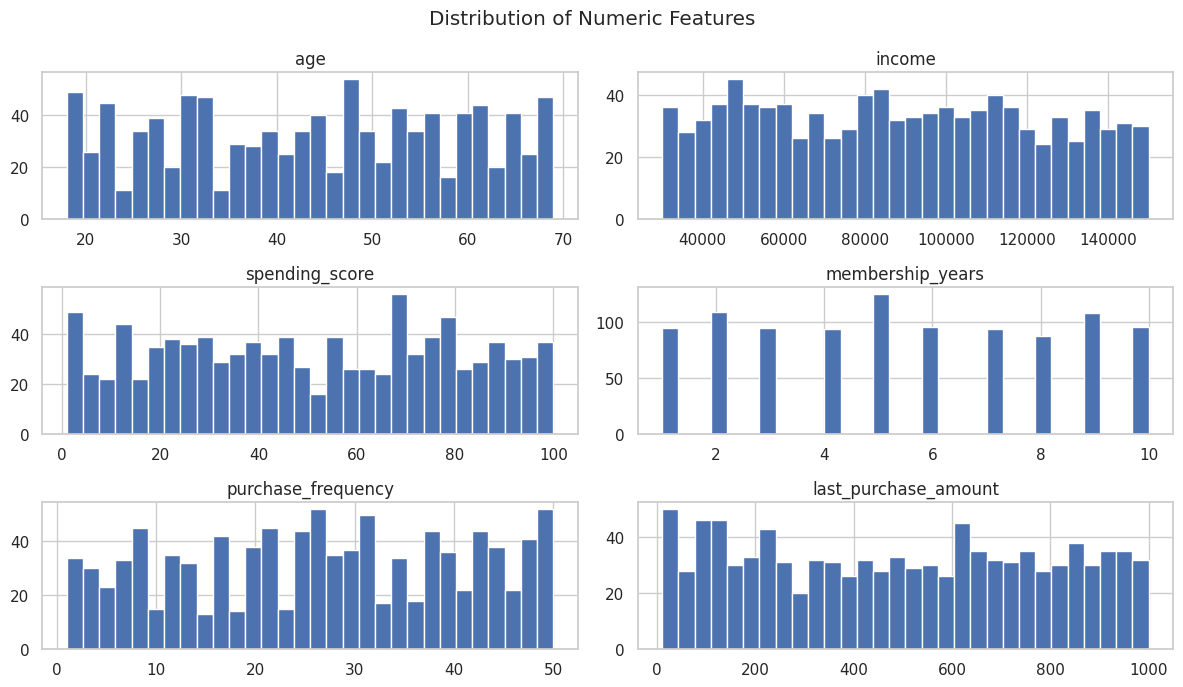

In [ ]:
print(df[num_cols].describe())

df[num_cols].hist(bins=30, figsize=(12, 7))
plt.suptitle("Distribution of Numeric Features")
plt.tight_layout()
plt.show()

In [ ]:
features = df[num_cols].copy()
features = features.join(pd.get_dummies(df[cat_cols], drop_first=False).astype(int))

rfm = df.copy()

print("Feature matrix shape:", features.shape)
display(features.head())

Feature matrix shape: (1000, 14)


,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount,gender_Female,gender_Male,gender_Other,preferred_category_Clothing,preferred_category_Electronics,preferred_category_Groceries,preferred_category_Home & Garden,preferred_category_Sports
id,,,,,,,,,,,,,,
1,38,99342,90,3,24,113.53,1,0,0,0,0,1,0,0
2,21,78852,60,2,42,41.93,1,0,0,0,0,0,0,1
3,60,126573,30,2,28,424.36,1,0,0,1,0,0,0,0
4,40,47099,74,9,5,991.93,0,0,1,0,0,0,1,0
5,65,140621,21,3,25,347.08,1,0,0,0,1,0,0,0


In [ ]:
features_log = features.copy()
for c in num_cols:
    if features[c].min() >= 0 and features[c].skew() > 1:
        features_log[c] = np.log1p(features[c])
        print("log1p applied to:", c)

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_log)

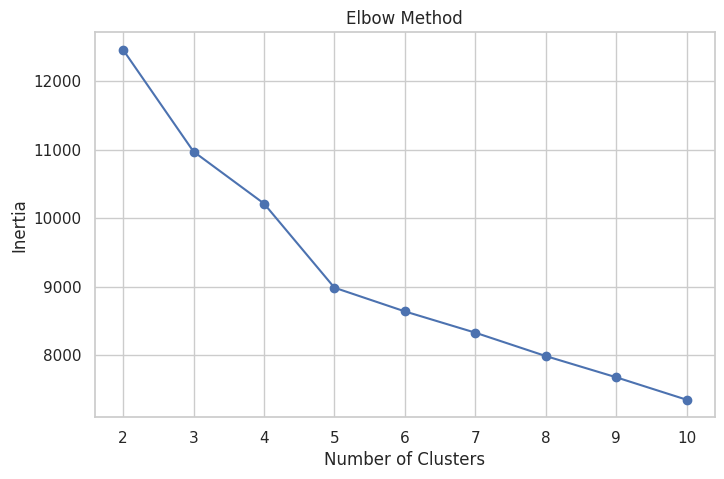

In [ ]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()


,K,Silhouette Score
0,2,0.111872
1,3,0.163607
2,4,0.190242
3,5,0.237556
4,6,0.194668
5,7,0.177646
6,8,0.170661
7,9,0.183588
8,10,0.202211


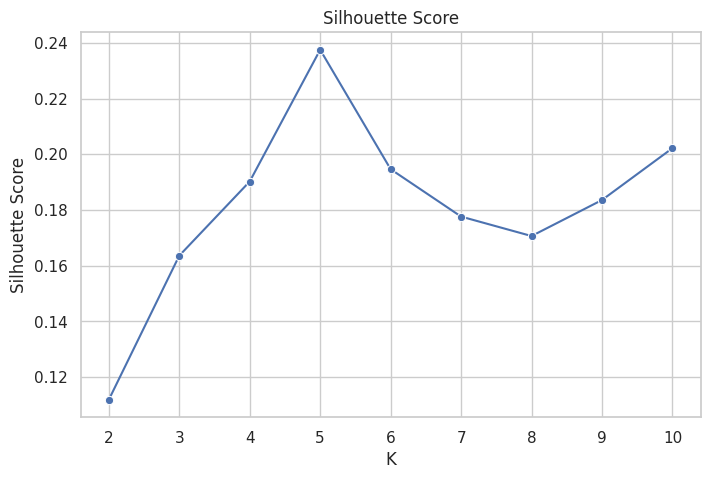

In [ ]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled, labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )
    silhouette_results.append((k, score))

silhouette_df = pd.DataFrame(silhouette_results, columns=["K", "Silhouette Score"])
display(silhouette_df)

plt.figure(figsize=(8, 5))
sns.lineplot(data=silhouette_df, x="K", y="Silhouette Score", marker="o")
plt.title("Silhouette Score")
plt.show()


In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(rfm["KMeans_Cluster"].value_counts())


K-Means Cluster Counts:
KMeans_Cluster
1    369
2    215
3    210
0    206
Name: count, dtype: int64


Explained Variance:
[0.11282396 0.1083347 ]
Total Variance: 0.2211586630598564


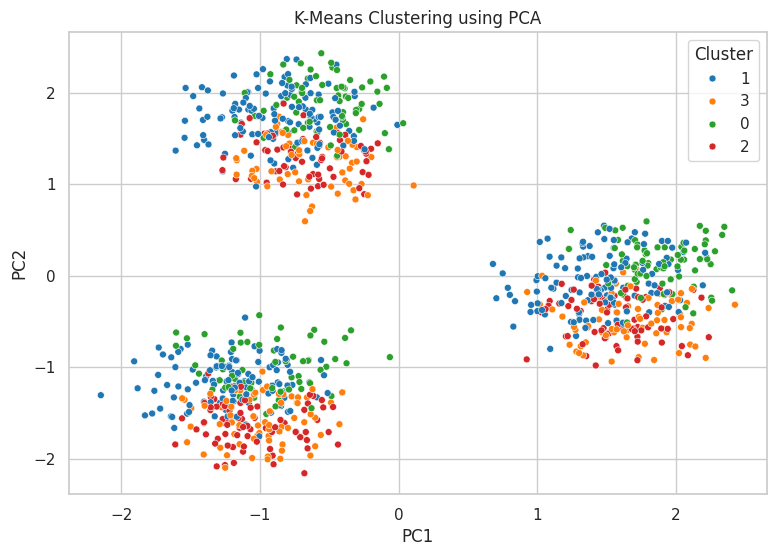

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance:")
print(pca.explained_variance_ratio_)
print("Total Variance:", pca.explained_variance_ratio_.sum())

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=rfm.index)
pca_df["Cluster"] = rfm["KMeans_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25)
plt.title("K-Means Clustering using PCA")
plt.show()


In [ ]:
dbscan = DBSCAN(eps=0.7, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN Cluster Counts:")
print(rfm["DBSCAN_Cluster"].value_counts())
print("Number of Clusters:", len(set(dbscan_labels) - {-1}))
print("Noise Points:", (dbscan_labels == -1).sum())


DBSCAN Cluster Counts:
DBSCAN_Cluster
-1    1000
Name: count, dtype: int64
Number of Clusters: 0
Noise Points: 1000


In [ ]:
dbscan_results = []

for eps in [0.5, 0.7, 1.0, 1.2, 1.5, 2.0]:
    for min_samples in [5, 10, 15]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        clusters = len(set(labels) - {-1})
        noise_percent = np.mean(labels == -1) * 100
        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": clusters,
            "noise_percent": round(noise_percent, 2)
        })

dbscan_results_df = pd.DataFrame(dbscan_results)
display(dbscan_results_df)


,eps,min_samples,clusters,noise_percent
0,0.5,5,0,100.0
1,0.5,10,0,100.0
2,0.5,15,0,100.0
3,0.7,5,0,100.0
4,0.7,10,0,100.0
5,0.7,15,0,100.0
6,1.0,5,0,100.0
7,1.0,10,0,100.0
8,1.0,15,0,100.0
9,1.2,5,0,100.0


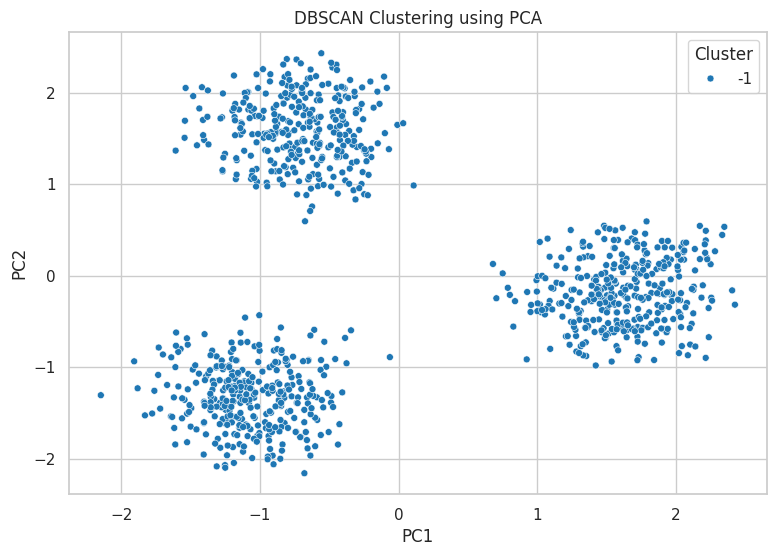

In [ ]:
pca_dbscan_df = pca_df.copy()
pca_dbscan_df["Cluster"] = rfm["DBSCAN_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_dbscan_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25)
plt.title("DBSCAN Clustering using PCA")
plt.show()


In [ ]:
def evaluate_clusters(X, labels):
    labels = np.asarray(labels)
    mask = labels != -1

    X_eval = X[mask]
    labels_eval = labels[mask]

    n_clusters = len(np.unique(labels_eval))

    if n_clusters < 2 or n_clusters >= len(labels_eval):
        score = np.nan
    else:
        score = silhouette_score(
            X_eval, labels_eval,
            sample_size=min(5000, len(X_eval)),
            random_state=42
        )

    return {
        "Clusters": n_clusters,
        "Noise Percentage": np.mean(labels == -1) * 100,
        "Silhouette Score": score
    }


print("K-Means:", evaluate_clusters(X_scaled, rfm["KMeans_Cluster"]))
print("DBSCAN:", evaluate_clusters(X_scaled, rfm["DBSCAN_Cluster"]))


K-Means: {'Clusters': 4, 'Noise Percentage': np.float64(0.0), 'Silhouette Score': np.float64(0.19024197069547108)}
DBSCAN: {'Clusters': 0, 'Noise Percentage': np.float64(100.0), 'Silhouette Score': nan}


In [ ]:
sample_size = min(5000, len(rfm))
rng = np.random.default_rng(42)
sample_positions = np.sort(rng.choice(len(rfm), size=sample_size, replace=False))

X_tsne_input = X_scaled[sample_positions]
sample_index = rfm.index[sample_positions]

perplexity = min(30, max(5, (sample_size - 1) // 3))

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = pd.DataFrame(X_tsne, columns=["TSNE1", "TSNE2"], index=sample_index)
tsne_df["KMeans_Cluster"] = rfm.loc[sample_index, "KMeans_Cluster"].astype(str)
tsne_df["DBSCAN_Cluster"] = rfm.loc[sample_index, "DBSCAN_Cluster"].astype(str)


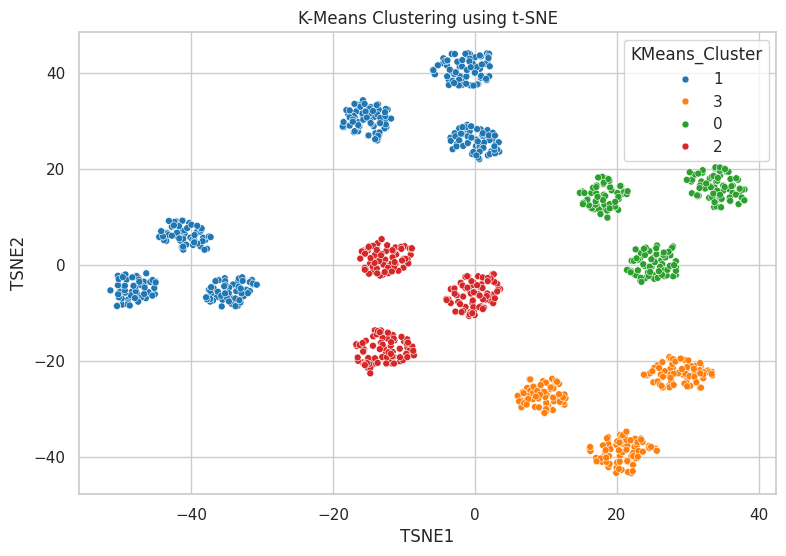

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="KMeans_Cluster", palette="tab10", s=25)
plt.title("K-Means Clustering using t-SNE")
plt.show()


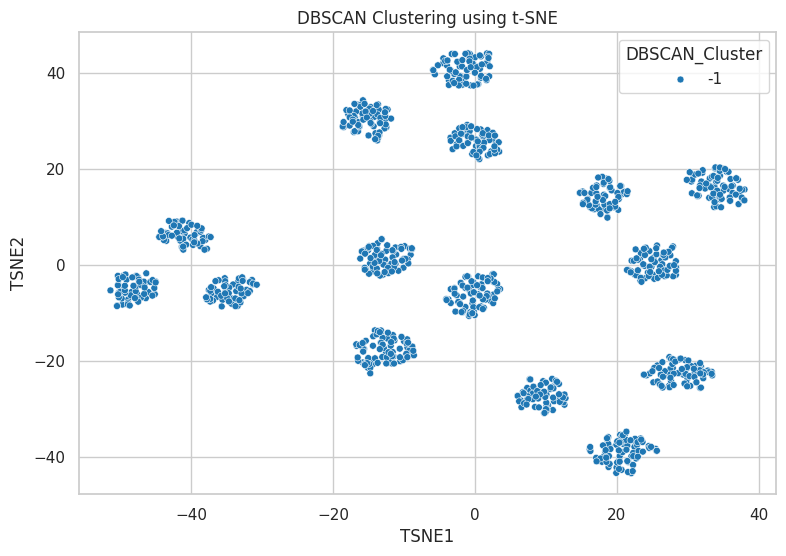

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="DBSCAN_Cluster", palette="tab10", s=25)
plt.title("DBSCAN Clustering using t-SNE")
plt.show()


In [ ]:
kmeans_profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("age", "size"),
    Avg_Age=("age", "mean"),
    Avg_Income=("income", "mean"),
    Avg_Spending_Score=("spending_score", "mean"),
    Avg_Membership_Years=("membership_years", "mean"),
    Avg_Purchase_Frequency=("purchase_frequency", "mean"),
    Avg_Last_Purchase=("last_purchase_amount", "mean"),
    Median_Income=("income", "median"),
    Median_Spending_Score=("spending_score", "median"),
    Median_Membership_Years=("membership_years", "median"),
    Median_Purchase_Frequency=("purchase_frequency", "median"),
    Median_Last_Purchase=("last_purchase_amount", "median")
).round(2)

kmeans_profile["Customer_Percent"] = (100 * kmeans_profile["Customers"] / len(rfm)).round(2)
display(kmeans_profile)

# Categorical mix per cluster
display(pd.crosstab(rfm["KMeans_Cluster"], rfm["preferred_category"], normalize="index").round(2))
display(pd.crosstab(rfm["KMeans_Cluster"], rfm["gender"], normalize="index").round(2))

,Customers,Avg_Age,Avg_Income,Avg_Spending_Score,Avg_Membership_Years,Avg_Purchase_Frequency,Avg_Last_Purchase,Median_Income,Median_Spending_Score,Median_Membership_Years,Median_Purchase_Frequency,Median_Last_Purchase,Customer_Percent
KMeans_Cluster,,,,,,,,,,,,,
0,206,43.35,88900.51,49.14,5.22,26.45,505.60,86289.5,46.5,5.0,28.0,506.78,20.6
1,369,44.25,88455.51,51.59,5.40,26.48,488.37,88312.0,53.0,5.0,27.0,486.25,36.9
2,215,43.08,89111.34,50.30,5.80,26.43,496.63,90389.0,47.0,6.0,27.0,506.70,21.5
3,210,44.10,87563.20,51.01,5.48,27.11,481.95,85481.5,49.5,5.0,28.0,484.46,21.0


preferred_category,Clothing,Electronics,Groceries,Home & Garden,Sports
KMeans_Cluster,,,,,
0,0.00,0.0,0.00,1.0,0.0
1,0.46,0.0,0.54,0.0,0.0
2,0.00,1.0,0.00,0.0,0.0
3,0.00,0.0,0.00,0.0,1.0


gender,Female,Male,Other
KMeans_Cluster,,,
0,0.33,0.37,0.30
1,0.33,0.34,0.33
2,0.30,0.35,0.34
3,0.29,0.37,0.34


In [ ]:
dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customers=("age", "size"),
    Avg_Age=("age", "mean"),
    Avg_Income=("income", "mean"),
    Avg_Spending_Score=("spending_score", "mean"),
    Avg_Membership_Years=("membership_years", "mean"),
    Avg_Purchase_Frequency=("purchase_frequency", "mean"),
    Avg_Last_Purchase=("last_purchase_amount", "mean"),
    Median_Income=("income", "median"),
    Median_Spending_Score=("spending_score", "median"),
    Median_Membership_Years=("membership_years", "median"),
    Median_Purchase_Frequency=("purchase_frequency", "median"),
    Median_Last_Purchase=("last_purchase_amount", "median")
).round(2)

dbscan_profile["Customer_Percent"] = (100 * dbscan_profile["Customers"] / len(rfm)).round(2)
display(dbscan_profile)

,Customers,Avg_Age,Avg_Income,Avg_Spending_Score,Avg_Membership_Years,Avg_Purchase_Frequency,Avg_Last_Purchase,Median_Income,Median_Spending_Score,Median_Membership_Years,Median_Purchase_Frequency,Median_Last_Purchase,Customer_Percent
DBSCAN_Cluster,,,,,,,,,,,,,
-1,1000,43.78,88500.8,50.68,5.47,26.6,492.35,87845.5,50.0,5.0,27.0,491.6,100.0


In [ ]:
overall_medians = rfm[["income", "spending_score", "purchase_frequency", "membership_years"]].median()


def draft_persona(row):
    high_income = row["Median_Income"] >= overall_medians["income"]
    high_spend = row["Median_Spending_Score"] >= overall_medians["spending_score"]
    frequent = row["Median_Purchase_Frequency"] >= overall_medians["purchase_frequency"]
    loyal = row["Median_Membership_Years"] >= overall_medians["membership_years"]

    if high_spend and frequent and loyal:
        return ("Loyal High-Value Customers",
                "VIP rewards, early access and loyalty benefits")
    elif high_income and not high_spend:
        return ("Affluent Under-Spenders",
                "Premium product recommendations and targeted upsell offers")
    elif high_spend and not loyal:
        return ("New Big Spenders",
                "Onboarding perks and membership-retention incentives")
    elif not high_spend and not frequent:
        return ("Low-Engagement Customers",
                "Low-cost email campaigns and relevant bundles")
    else:
        return ("Steady Mid-Value Customers",
                "Cross-sell campaigns and purchase-frequency incentives")


persona_rows = []

for cluster_id, row in kmeans_profile.iterrows():
    name, action = draft_persona(row)
    persona_rows.append({
        "Cluster": cluster_id,
        "Customer Persona": name,
        "Marketing Strategy": action
    })

persona_table = pd.DataFrame(persona_rows)
display(persona_table)

,Cluster,Customer Persona,Marketing Strategy
0,0,Steady Mid-Value Customers,Cross-sell campaigns and purchase-frequency in...
1,1,Loyal High-Value Customers,"VIP rewards, early access and loyalty benefits"
2,2,Affluent Under-Spenders,Premium product recommendations and targeted u...
3,3,Steady Mid-Value Customers,Cross-sell campaigns and purchase-frequency in...


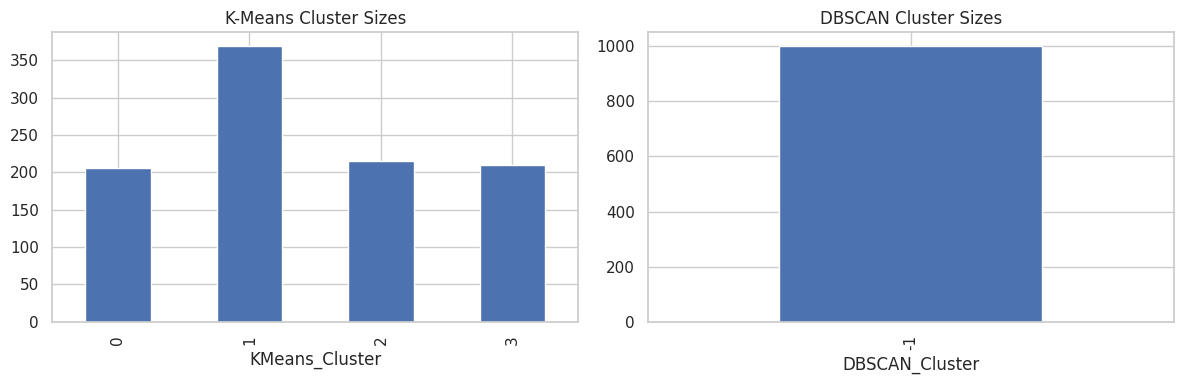

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rfm["KMeans_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="K-Means Cluster Sizes")

rfm["DBSCAN_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="DBSCAN Cluster Sizes")

plt.tight_layout()
plt.show()


In [ ]:
rfm.to_csv("customer_segments.csv")
kmeans_profile.to_csv("kmeans_cluster_profile.csv")
dbscan_profile.to_csv("dbscan_cluster_profile.csv")
persona_table.to_csv("marketing_personas.csv", index=False)
pca_df.to_csv("pca_visualization.csv")
tsne_df.to_csv("tsne_visualization.csv")

print("All project files exported successfully.")


All project files exported successfully.


In [ ]:
files.download("customer_segments.csv")
files.download("kmeans_cluster_profile.csv")
files.download("dbscan_cluster_profile.csv")
files.download("marketing_personas.csv")
files.download("pca_visualization.csv")
files.download("tsne_visualization.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>